# 1. Problem

Recover the regularized apo ecSecB residue protection field from real overlapping peptide HDX measurements. There is no independent residue ground truth. The complete146-site field includes123physical exchange sites and23auxiliary TV supports, which are not interpreted as physical energies. Version2 explicitly corrects a proven missing solvent-label fraction in the original forward model.

In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.visualization import comparison,correction_limits
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
print('Runtime',sys.executable)


Runtime D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


# 2. Data

All63peptides and seven native exposures are retained. Fully deuterated control is independent raw calibration; intrinsic rates are an unstructured-sequence reference at pH8 and303.15K. Capacity includes the known solvent deuterium fraction0.9. No calibration is obtained from the reconstructed field.

In [2]:
from src.preprocessing import load_data
raw,observed=load_data(ROOT/'data/raw_data.npz')
print('Peptides, exposures:', observed.shape,'field sites:',raw['residue_number'].size)
print('Exposure (s):',raw['time_s'])
print('Physical / auxiliary:',raw['exchanges'].sum(),(~raw['exchanges']).sum())
print('Finite-label capacity maximum error (Da):',np.max(np.abs(.9*raw['membership']@(raw['intrinsic_rates']>0)-raw['capacity'])))

Peptides, exposures: (63, 7) field sites: 146
Exposure (s): [   0.        10.02      30.        60.       300.       600.
 6000.00048]
Physical / auxiliary: 123 23
Finite-label capacity maximum error (Da): 1.7763568394002505e-15


# 3. Physics

For peptide p, residue j and exposure m, the physical uptake is

$$
a_{pm}(G)=f\sum_j X_{pj}\left[1-\exp\left(-\frac{k_jt_m}{1+\exp(G_j/(RT))}\right)\right].
$$

Here X is dimensionless membership, k is intrinsic rate in inverse seconds, t is seconds, G is J/mol, R=8.31446261815324J/(mol K), T=303.15K and f=.9. Corrected observations y=uC/F are in Da. The t=0 limit is zero and infinite-time limit is f times the exchangeable site count, exactly the independent capacity C. The original implementation omitted f from this forward operator despite including it in capacity; its V1 result is retained only as a documented counterfactual.


# 4. Method

The selected corrected standard minimizes

$$
J=\frac{1}{441}\sum_{p,m}(a_{pm}-y_{pm})^2+\frac{2\times10^{-4}}{145}\sum_{j=1}^{145}|G_{j+1}-G_j|.
$$

The coefficient has units Da squared mol/J. All146sites and145adjacencies are retained. Initialization actively fits multi-exponential fractional-uptake curves from public observations. Joint float64 Nesterov SGD uses the original complete budget and stopping rule. The independent corrected source run uses algebraically scaled units: yNative=y/f, TVNative=TV/f squared, learningRateNative=learningRate times f squared and stopNative=stop/f squared. Thus Jraw=f squared JNative and the physical updates agree. This is an explicit scientific correction, not an unmodified original protocol. The next cell runs the entire cleaned initialization and inverse fit.


In [3]:
start=time.perf_counter()
raw,observed,initial,energy,uptake,history,objective=run(ROOT)
fresh_seconds=time.perf_counter()-start
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
print('Fresh local runtime (s):',fresh_seconds,'actual iterations:',len(history))
print(json.dumps(report,indent=2)); assert exit_code==0


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch13_20261030\_staging\biology\secb_hdx_residue_protection_field\src\initialization.py:13: RuntimeWarning: overflow encountered in exp
  k1=fsolve(lambda k:(1-np.exp(-k*t[2]))-d[2],.5)[0]
D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch13_20261030\_staging\biology\secb_hdx_residue_protection_field\src\initialization.py:14: RuntimeWarning: overflow encountered in exp
  k2=fsolve(lambda k:(1-(.5*np.exp(-k1*t[-2])+.5*np.exp(-k*t[-2])))-d[-2],.05)[0]
D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch13_20261030\_staging\biology\secb_hdx_residue_protection_field\src\initialization.py:21: RuntimeWarning: overflow encountered in square
  return .5*np.sum((pred-d)**2)
D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Lib\site-packages\scipy\optimize\_optimize.py:2540: RuntimeWarning: invalid value encountered in scalar multiply
  tmp2 = (x - v) * (fx - fw)
D:\yan1\agent\AutoSkill\imaging-101-mainta

Fresh local runtime (s): 64.89768910000566 actual iterations: 70198
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "objective": 1.0259098940202644,
    "forward_observation_normalized_l2": 5.921512345660463e-17
  },
  "thresholds": {
    "objective": {
      "comparison": "<=",
      "boundary": 1.0361689959301181
    },
    "forward_observation_normalized_l2": {
      "comparison": "<=",
      "boundary": 1e-09
    }
  },
  "errors": []
}


# 5. Results

The independently executed corrected-source method is a reference, not molecular truth. The older uncorrected half-time initialization comparison is explicitly V1 and has a different physical convention; its objective must not be ranked against V2. Curves and residuals below use freshly reconstructed V2 results.

Measurement | Source corrected V2 | Fresh corrected V2
Objective | 1.025909896960513 | 1.0259098940202644
Iterations | 70198 | 70198
MSE (Da squared) | 0.6608051501423635 | 0.6608051459306558
TV contribution (Da squared) | 0.3651047468181494 | 0.36510474808960874


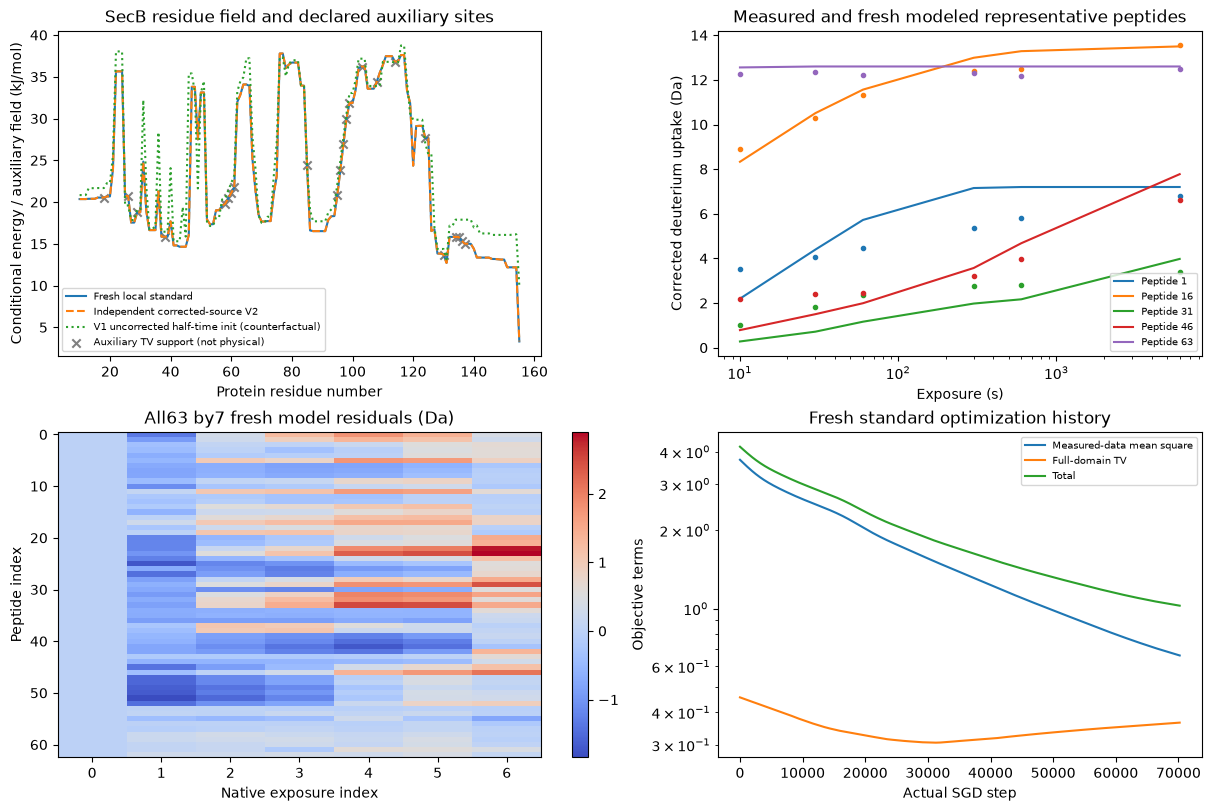

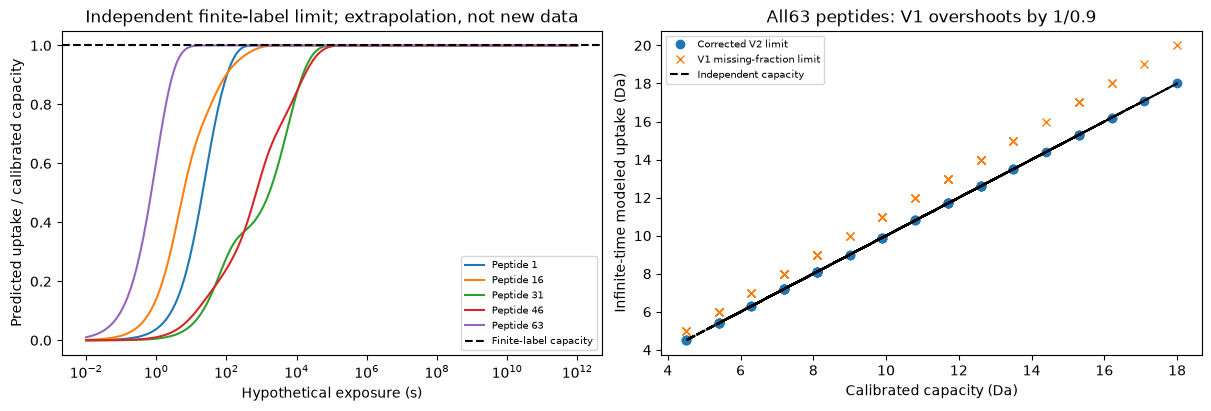

In [4]:
up=np.load(ROOT/'notebooks/reference_outputs/upstream.npz')
old=np.load(ROOT/'notebooks/reference_outputs/upstream_halfinit.npz')
print('Measurement | Source corrected V2 | Fresh corrected V2')
print('Objective | 1.025909896960513 |', objective)
print('Iterations | 70198 |',len(history))
print('MSE (Da squared) | 0.6608051501423635 |',np.mean((uptake-observed)**2))
print('TV contribution (Da squared) | 0.3651047468181494 |',2e-4*np.mean(np.abs(np.diff(energy))))
fig=comparison(raw,observed,energy,uptake,history,up['output_auxiliary'],old['output_auxiliary']);plt.show()
fig2=correction_limits(raw,observed,energy);plt.show()

# 6. Conclusion

The complete local fit agrees numerically with the independently executed corrected-source standard under the same physical labeling convention. Finite-label limits and control independence are verified separately from parity. The result remains a regularized, conditional exchange model: peptide averaging and sparse coverage do not uniquely determine individual residue energies. Auxiliary sites and the wrong-convention V1 comparison are marked explicitly. Residual structure, the intrinsic-rate convention and experimental control assumptions limit physical interpretation; passing a method-objective bound does not establish atomic truth.